Code to add to the raw dlc h5 data a new 'bodypart' named weigthed, which is the nose bodypart if its likelihood is greater than 0.3 and a weigted sum according to the likelihoods of all other bodyparts if it less than 0.3.
We then can define this bodypart in the NaviGraph to get less NaN values in the result (now we'll get Nan only for row where all values in DC where NaN)

In [20]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt


In [65]:
folder_path = "/var/home/almogmeir/Documents/M.Sc/Project/DLC/NPM12_2025_05_13_17_07_50/"
file_name = "NPM12_2025_05_13_17_07_50_stitchedDLC_Resnet101_NeuroMazeMar26shuffle8_snapshot_170_filtered"

In [66]:
# Read the h5 file, update the path to the raw h5 DLC outputs
h5_file = pd.read_hdf(folder_path + file_name + ".h5")

In [67]:
h5_file[130:133]

scorer    DLC_Resnet101_NeuroMazeMar26shuffle8_snapshot_170              \
bodyparts                                              nose               
coords                                                    x           y   
130                                              634.250061  422.547668   
131                                              634.303711  421.532990   
132                                              634.440369  419.355164   

scorer                                                               \
bodyparts                  ear_L                              ear_R   
coords    likelihood           x           y likelihood           x   
130         0.447508  628.929016  441.536102   0.689261  643.720093   
131         0.557650  630.058472  441.031342   0.611713  644.083496   
132         0.514346  630.627014  438.899048   0.542338  644.400696   

scorer                                                              \
bodyparts                          mid_body                          
coords             y likelihood           x           y likelihood   
130        431.47168   0.501545  637.573608  456.055725   0.708118   
131        431.47168   0.461066  639.244568  454.991211   0.681915   
132        431.47168   0.462758  640.053833  453.071747   0.617506   

scorer                                                                \
bodyparts   tail_base                         head_stage               
coords              x           y likelihood           x           y   
130        609.422729  468.025482   0.335960  616.230652  432.179535   
131        609.422729  467.218323   0.406995  616.230652  433.523254   
132        467.977905  198.747452   0.422405  616.299255  433.523254   

scorer                
bodyparts             
coords    likelihood  
130         0.454807  
131         0.605718  
132         0.491777

In [68]:
# Update to be the actual file name according to the first index column value of the h5 table
file_name = 'DLC_Resnet101_NeuroMazeMar26shuffle8_snapshot_170'

# Load the DataFrame from the HDF5 file
dlc_raw_h5 = h5_file[file_name]

# Extract the MultiIndex from the first two rows
multi_index = pd.MultiIndex.from_arrays([dlc_raw_h5.iloc[0], dlc_raw_h5.iloc[1]])

# Convert the data to numeric, errors='coerce' will turn non-numeric values into NaN
dlc_raw_h5 = dlc_raw_h5.apply(pd.to_numeric, errors='coerce')

new_index = pd.MultiIndex.from_tuples([
        ('weighted', 'x'),
        ('weighted', 'y'),
        ('weighted', 'likelihood')
    ])

new_index_df = pd.DataFrame(np.nan, index=range(len(dlc_raw_h5)), columns=new_index)


# Concatenate the original DataFrame with the new columns DataFrame
# dlc_raw_h5 = pd.concat([dlc_raw_h5, new_columns], axis=1)

dlc_raw_h5 = pd.concat([dlc_raw_h5, new_index_df], axis=1)
dlc_raw_h5

nose                              ear_L                          \
                 x           y likelihood           x            y likelihood   
0       357.991852  102.027466   0.096844  172.259048   631.571716   0.170674   
1       357.991852  102.027466   0.132439  697.261047  1016.736267   0.179482   
2       357.991852  102.027466   0.126299  698.825134  1016.744507   0.199933   
3       357.771729  100.034554   0.118914  698.842468  1016.744507   0.200358   
4       357.589417  100.034554   0.130283  698.871460  1016.740295   0.195734   
...            ...         ...        ...         ...          ...        ...   
106269  357.377411  100.441414   0.120484  357.336548   116.402100   0.108573   
106270  357.373993  100.430611   0.119981  357.336548   116.405815   0.109413   
106271  357.392914  100.430611   0.115607  357.340393   116.405815   0.108022   
106272  357.392914  100.316513   0.102566  357.340393   116.402100   0.100664   
106273  357.295258   99.633568   0.102977  357.030273   116.397072   0.100811   

             ear_R                            mid_body  ...             \
                 x            y likelihood           x  ... likelihood   
0       690.456421   408.303253   0.176608  155.626831  ...   0.273964   
1       692.241333  1022.014832   0.199754  674.115295  ...   0.128388   
2       692.244202  1022.014832   0.194973  674.404846  ...   0.108675   
3       692.244202  1022.016174   0.195047  674.413818  ...   0.109132   
4       692.523621  1022.037292   0.194625  674.413818  ...   0.104665   
...            ...          ...        ...         ...  ...        ...   
106269  365.039001   101.905685   0.203116  151.276947  ...   0.167863   
106270  365.039001   101.899910   0.203860  151.276031  ...   0.168036   
106271  365.015869   101.899910   0.200736  151.276947  ...   0.183020   
106272  364.862885   101.845116   0.188698  151.276947  ...   0.189102   
106273  364.720276   101.725418   0.187232  151.133591  ...   0.165282   

         tail_base                          head_stage                         \
                 x            y likelihood           x           y likelihood   
0       147.016876   666.511353   0.282438  377.326202  110.977829   0.240855   
1       654.800903  1016.053345   0.239948  377.326202  111.512482   0.344913   
2       655.694092  1016.053345   0.220271  377.345459  111.512482   0.308613   
3       655.696899  1016.053345   0.220511  377.326202  111.512482   0.329658   
4       655.807129  1015.923035   0.216474  377.246918  111.512695   0.315672   
...            ...          ...        ...         ...         ...        ...   
106269  147.032730   666.404053   0.188263  378.127625  110.936340   0.391155   
106270  147.031937   666.404053   0.188591  378.127625  110.937164   0.388132   
106271  147.016418   666.403625   0.195708  378.127625  110.946671   0.386863   
106272  146.916824   666.399536   0.215461  378.004211  110.937164   0.359986   
106273  146.659332   666.370300   0.193566  377.985626  110.937164   0.372175   

       weighted                 
              x   y likelihood  
0           NaN NaN        NaN  
1           NaN NaN        NaN  
2           NaN NaN        NaN  
3           NaN NaN        NaN  
4           NaN NaN        NaN  
...         ...  ..        ...  
106269      NaN NaN        NaN  
106270      NaN NaN        NaN  
106271      NaN NaN        NaN  
106272      NaN NaN        NaN  
106273      NaN NaN        NaN  

[106274 rows x 21 columns]

In [ ]:
# def calculate_weighted_coordinates(row):
#     body_parts = ['ear_R', 'ear_L', 'mid_body', 'tail_base', 'head_stage']
#     total_weight = 0
#     weighted_x = 0
#     weighted_y = 0
#     weighted_likelihood = 0
#     likelihoods = []

#     for part in body_parts:
#         likelihood = row[part]['likelihood']
#         likelihoods.append(likelihood)
#         if likelihood > 0:
#             weighted_x += row[part]['x'] * likelihood
#             weighted_y += row[part]['y'] * likelihood
#             total_weight += likelihood

#     if total_weight > 0:
#         weighted_x /= total_weight
#         weighted_y /= total_weight
#         weighted_likelihood = sum([likelihood * (likelihood / total_weight) for likelihood in likelihoods])
#     likelihoods = []

#     return (weighted_x, weighted_y, weighted_likelihood)

# # # Apply the function to each row in the dataframe
# # dlc_raw_h5['weighted'][['x', 'y', 'likelihood']] = dlc_raw_h5.apply(
# #     lambda row: calculate_weighted_coordinates(row) if row['nose']['likelihood'] < 0.3 else pd.Series([row['nose']['x'], row['nose']['y'], row['nose']['likelihood']]),
# #     axis=1
# # )

# for i, row in enumerate(dlc_raw_h5.iterrows()):
#     if row[1]['nose']['likelihood'] >= 0.3:
#         dlc_raw_h5.loc[i, ('weighted', ['x', 'y', 'likelihood'])] = (row[1]['nose']['x'], row[1]['nose']['y'], row[1]['nose']['likelihood'])
#     else:
#         dlc_raw_h5.loc[i, ('weighted', ['x', 'y', 'likelihood'])] = calculate_weighted_coordinates(row[1])

# # Display the updated dataframe
# dlc_raw_h5


nose                               ear_L              \
                  x           y likelihood            x           y   
0       1297.983154  983.381165   0.431004  1301.035278  989.675110   
1       1297.806885  983.313232   0.439588  1300.918945  989.591187   
2       1297.884521  983.149963   0.440869  1300.909668  989.560181   
3       1297.929077  983.143921   0.439708  1300.972046  989.524048   
4       1298.071167  983.272278   0.433305  1301.043213  989.605774   
...             ...         ...        ...          ...         ...   
143548  1298.862549  985.579956   0.424271   386.129974  504.064331   
143549   410.521240  496.422302   0.458756   386.586365  503.284851   
143550  1298.880005  985.566162   0.425120   387.366455  502.538696   
143551  1298.762939  985.504517   0.430501   388.013794  501.874146   
143552  1298.861206  985.582581   0.424186   389.599060  501.076813   

                        ear_R                             mid_body  ...  \
       likelihood           x            y likelihood            x  ...   
0        0.289643   21.653118  1006.018494   0.296977  1226.836914  ...   
1        0.289184   21.494226  1005.729980   0.284459     4.938797  ...   
2        0.294290   21.547333  1005.828674   0.283248     4.950881  ...   
3        0.292058   21.547070  1005.827820   0.282394     4.946735  ...   
4        0.288232   21.660812  1006.043152   0.292009     4.816325  ...   
...           ...         ...          ...        ...          ...  ...   
143548   0.893327  401.267181   519.348633   0.942303   378.786194  ...   
143549   0.938769  402.240509   520.156433   0.969324   378.646454  ...   
143550   0.905918  403.342651   518.341431   0.981317   378.386292  ...   
143551   0.883200  403.840210   518.144714   0.982116   378.901367  ...   
143552   0.891525  404.555450   517.431152   0.972554   379.564880  ...   

                     tail_base                         head_stage              \
       likelihood            x           y likelihood           x           y   
0        0.244646  1212.028687   28.951492   0.418888    9.371573  982.402710   
1        0.229472  1211.572998   28.360371   0.425376    9.244394  982.424316   
2        0.225801  1211.583740   28.429068   0.426016    9.235188  982.434509   
3        0.224703  1211.598633   28.423143   0.423962    9.234289  982.404175   
4        0.214242  1211.569336   28.364849   0.421606    9.320097  982.334961   
...           ...          ...         ...        ...         ...         ...   
143548   0.772520   358.325134  550.428040   0.571847  414.531860  496.007355   
143549   0.743751   358.882996  549.892883   0.562917  414.725494  496.876526   
143550   0.709996   358.746521  548.639221   0.626313  416.623474  495.577667   
143551   0.719511   359.702393  548.057007   0.667162  417.021088  495.295380   
143552   0.758008   359.798431  546.451050   0.638189  417.027588  495.686829   

                      weighted                         
       likelihood            x           y likelihood  
0        0.681662  1297.983154  983.381165   0.431004  
1        0.679922  1297.806885  983.313232   0.439588  
2        0.674294  1297.884521  983.149963   0.440869  
3        0.672150  1297.929077  983.143921   0.439708  
4        0.674633  1298.071167  983.272278   0.433305  
...           ...          ...         ...        ...  
143548   0.848309  1298.862549  985.579956   0.424271  
143549   0.887016   410.521240  496.422302   0.458756  
143550   0.922607  1298.880005  985.566162   0.425120  
143551   0.883615  1298.762939  985.504517   0.430501  
143552   0.899303  1298.861206  985.582581   0.424186  

[143553 rows x 21 columns]

In [69]:
def set_likelihood_to_zero_outside_boundary(df, bodypart, x_min, x_max, y_min, y_max):
    """
    Sets the likelihood of a bodypart to 0 if its coordinates are outside the given boundary.

    Parameters:
    df (pd.DataFrame): The dataframe containing the bodypart data.
    bodypart (str): The bodypart to check.
    x_min (float): Minimum x-coordinate boundary.
    x_max (float): Maximum x-coordinate boundary.
    y_min (float): Minimum y-coordinate boundary.
    y_max (float): Maximum y-coordinate boundary.
    """
    outside_boundary = (df[(bodypart, 'x')] < x_min) | (df[(bodypart, 'x')] > x_max) | \
                       (df[(bodypart, 'y')] < y_min) | (df[(bodypart, 'y')] > y_max)
    df.loc[outside_boundary, (bodypart, 'likelihood')] = 0

In [70]:
for bodypart in ['ear_R', 'ear_L', 'mid_body', 'tail_base', 'nose', 'head_stage']:
    set_likelihood_to_zero_outside_boundary(dlc_raw_h5, bodypart, 78, 1180, 60, 860)

In [ ]:
def calculate_weighted_coordinates(row):
    nose_likelihood = row['nose']['likelihood']
    head_stage_likelihood = row['head_stage']['likelihood']
    
    # If either nose or head_stage has a likelihood at least 0.6, pick the one with the higher likelihood.
    if nose_likelihood >= 0.6 or head_stage_likelihood >= 0.6:
        if nose_likelihood >= head_stage_likelihood:
            return (row['nose']['x'], row['nose']['y'], nose_likelihood)
        else:
            return (row['head_stage']['x'], row['head_stage']['y'], head_stage_likelihood)
    
    # Both nose and head_stage have low likelihood, so use weighted sum of all other body parts.
    body_parts = ['ear_R', 'ear_L', 'mid_body', 'tail_base']
    total_weight = 0
    weighted_x = 0
    weighted_y = 0
    likelihoods = []

    for part in body_parts:
        likelihood = row[part]['likelihood']
        likelihoods.append(likelihood)
        if likelihood > 0:
            weighted_x += row[part]['x'] * likelihood
            weighted_y += row[part]['y'] * likelihood
            total_weight += likelihood

    if total_weight > 0:
        weighted_x /= total_weight
        weighted_y /= total_weight
        weighted_likelihood = sum(likelihood * (likelihood / total_weight) for likelihood in likelihoods)
    else:
        weighted_likelihood = 0

    return (weighted_x, weighted_y, weighted_likelihood)

for i, row in enumerate(dlc_raw_h5.iterrows()):
    dlc_raw_h5.loc[i, ('weighted', ['x', 'y', 'likelihood'])] = calculate_weighted_coordinates(row[1])

# Display the updated dataframe
dlc_raw_h5

nose                              ear_L                          \
                 x           y likelihood           x            y likelihood   
0       357.991852  102.027466   0.096844  172.259048   631.571716   0.170674   
1       357.991852  102.027466   0.132439  697.261047  1016.736267   0.000000   
2       357.991852  102.027466   0.126299  698.825134  1016.744507   0.000000   
3       357.771729  100.034554   0.118914  698.842468  1016.744507   0.000000   
4       357.589417  100.034554   0.130283  698.871460  1016.740295   0.000000   
...            ...         ...        ...         ...          ...        ...   
106269  357.377411  100.441414   0.120484  357.336548   116.402100   0.108573   
106270  357.373993  100.430611   0.119981  357.336548   116.405815   0.109413   
106271  357.392914  100.430611   0.115607  357.340393   116.405815   0.108022   
106272  357.392914  100.316513   0.102566  357.340393   116.402100   0.100664   
106273  357.295258   99.633568   0.102977  357.030273   116.397072   0.100811   

             ear_R                            mid_body  ...             \
                 x            y likelihood           x  ... likelihood   
0       690.456421   408.303253   0.176608  155.626831  ...   0.273964   
1       692.241333  1022.014832   0.000000  674.115295  ...   0.000000   
2       692.244202  1022.014832   0.000000  674.404846  ...   0.000000   
3       692.244202  1022.016174   0.000000  674.413818  ...   0.000000   
4       692.523621  1022.037292   0.000000  674.413818  ...   0.000000   
...            ...          ...        ...         ...  ...        ...   
106269  365.039001   101.905685   0.203116  151.276947  ...   0.167863   
106270  365.039001   101.899910   0.203860  151.276031  ...   0.168036   
106271  365.015869   101.899910   0.200736  151.276947  ...   0.183020   
106272  364.862885   101.845116   0.188698  151.276947  ...   0.189102   
106273  364.720276   101.725418   0.187232  151.133591  ...   0.165282   

         tail_base                          head_stage                         \
                 x            y likelihood           x           y likelihood   
0       147.016876   666.511353   0.282438  377.326202  110.977829   0.240855   
1       654.800903  1016.053345   0.000000  377.326202  111.512482   0.344913   
2       655.694092  1016.053345   0.000000  377.345459  111.512482   0.308613   
3       655.696899  1016.053345   0.000000  377.326202  111.512482   0.329658   
4       655.807129  1015.923035   0.000000  377.246918  111.512695   0.315672   
...            ...          ...        ...         ...         ...        ...   
106269  147.032730   666.404053   0.188263  378.127625  110.936340   0.391155   
106270  147.031937   666.404053   0.188591  378.127625  110.937164   0.388132   
106271  147.016418   666.403625   0.195708  378.127625  110.946671   0.386863   
106272  146.916824   666.399536   0.215461  378.004211  110.937164   0.359986   
106273  146.659332   666.370300   0.193566  377.985626  110.937164   0.372175   

          weighted                         
                 x           y likelihood  
0       285.163397  499.923756   0.238662  
1       377.326202  111.512482   0.344913  
2       377.345459  111.512482   0.308613  
3       377.326202  111.512482   0.329658  
4       377.246918  111.512695   0.315672  
...            ...         ...        ...  
106269  296.442262  293.992310   0.254651  
106270  296.235263  294.412144   0.253281  
106271  292.842365  302.833094   0.254503  
106272  285.752784  319.571389   0.244340  
106273  292.743148  302.204626   0.243869  

[106274 rows x 21 columns]

In [72]:
dlc_raw_h5[dlc_raw_h5['head_stage']['likelihood'] < 0.6][1000:1010]

nose                               ear_L                         \
               x           y likelihood            x           y likelihood   
2590  358.650330  102.744133   0.127751  1036.260498  217.610764   0.360235   
2591  358.553986  102.688469   0.128259  1043.248779  190.604477   0.119569   
2592  357.370422  100.580093   0.106699  1043.675415  190.604477   0.162231   
2593  357.370422  100.580093   0.105950  1043.675415  190.604477   0.187066   
2594  357.325104  100.558319   0.108304  1043.675415  193.216827   0.163847   
2595  357.325104  100.558319   0.148795  1041.048950  197.677292   0.287959   
2596  357.363281  100.558319   0.109033  1034.727295  208.559814   0.140731   
2597  951.871277  199.167328   0.108677   984.928345  224.026962   0.205610   
2598  943.345337  212.092621   0.244292   967.784851  225.663757   0.328736   
2638  921.425842  471.850586   0.363063   937.383911  458.865662   0.552634   

           ear_R                            mid_body  ...             \
               x           y likelihood            x  ... likelihood   
2590  365.039734  207.190384   0.379218  1041.587646  ...   1.000000   
2591  364.973175  210.569077   0.150520  1035.882324  ...   1.000000   
2592  365.039734  210.569077   0.164981  1033.442871  ...   1.000000   
2593  365.039734  207.975998   0.162121  1029.882935  ...   0.844406   
2594  986.229858  211.789749   0.227256  1025.230835  ...   0.860275   
2595  986.229858  210.477753   0.331653  1019.946838  ...   0.839221   
2596  986.229858  210.068832   0.261929  1014.532715  ...   0.806259   
2597  978.414612  210.477753   0.360722  1007.134399  ...   0.739621   
2598  967.799194  211.191879   0.537295   998.681274  ...   0.764551   
2638  918.130127  455.199432   0.699150   930.691895  ...   1.000000   

        tail_base                         head_stage                         \
                x           y likelihood           x           y likelihood   
2590  1050.337769  173.787811   0.812724  377.849487  111.117767   0.455365   
2591  1052.497314  180.663330   0.838781  377.849487  111.116508   0.455414   
2592  1052.497314  184.668594   0.751229  377.847900  111.014145   0.354489   
2593  1052.497314  188.847580   0.741006  377.833740  111.008438   0.358880   
2594  1052.240601  194.285080   0.797792  377.830658  111.005417   0.360536   
2595  1046.638672  199.686478   0.590855  377.828094  111.008438   0.359539   
2596  1045.463989  207.691742   0.833191  377.828094  111.014145   0.363948   
2597  1040.543457  212.399765   0.873283  377.830658  111.027664   0.360105   
2598  1035.005859  216.001602   0.741344  935.249023  218.650253   0.543152   
2638   932.434998  405.191925   0.754956  924.604126  479.707672   0.579875   

     weighted                 
            x   y likelihood  
2590      NaN NaN        NaN  
2591      NaN NaN        NaN  
2592      NaN NaN        NaN  
2593      NaN NaN        NaN  
2594      NaN NaN        NaN  
2595      NaN NaN        NaN  
2596      NaN NaN        NaN  
2597      NaN NaN        NaN  
2598      NaN NaN        NaN  
2638      NaN NaN        NaN  

[10 rows x 21 columns]

In [62]:
# Restore the top level index (scorer) with the file name
h5_file = pd.concat({file_name: dlc_raw_h5}, axis=1)
# Restore the index column names
h5_file.columns.names = ['scorer', 'bodyparts', 'coords']
h5_file

scorer    DLC_Resnet101_NeuroMazeMar26shuffle8_snapshot_170              \
bodyparts                                              nose               
coords                                                    x           y   
0                                                357.991852  102.027466   
1                                                357.991852  102.027466   
2                                                357.991852  102.027466   
3                                                357.771729  100.034554   
4                                                357.589417  100.034554   
...                                                     ...         ...   
106269                                           357.377411  100.441414   
106270                                           357.373993  100.430611   
106271                                           357.392914  100.430611   
106272                                           357.392914  100.316513   
106273                                           357.295258   99.633568   

scorer                                                                \
bodyparts                  ear_L                               ear_R   
coords    likelihood           x            y likelihood           x   
0           0.096844  172.259048   631.571716   0.170674  690.456421   
1           0.132439  697.261047  1016.736267   0.000000  692.241333   
2           0.126299  698.825134  1016.744507   0.000000  692.244202   
3           0.118914  698.842468  1016.744507   0.000000  692.244202   
4           0.130283  698.871460  1016.740295   0.000000  692.523621   
...              ...         ...          ...        ...         ...   
106269      0.120484  357.336548   116.402100   0.108573  365.039001   
106270      0.119981  357.336548   116.405815   0.109413  365.039001   
106271      0.115607  357.340393   116.405815   0.108022  365.015869   
106272      0.102566  357.340393   116.402100   0.100664  364.862885   
106273      0.102977  357.030273   116.397072   0.100811  364.720276   

scorer                                         ...                         \
bodyparts                            mid_body  ...              tail_base   
coords               y likelihood           x  ... likelihood           x   
0           408.303253   0.176608  155.626831  ...   0.273964  147.016876   
1          1022.014832   0.000000  674.115295  ...   0.000000  654.800903   
2          1022.014832   0.000000  674.404846  ...   0.000000  655.694092   
3          1022.016174   0.000000  674.413818  ...   0.000000  655.696899   
4          1022.037292   0.000000  674.413818  ...   0.000000  655.807129   
...                ...        ...         ...  ...        ...         ...   
106269      101.905685   0.203116  151.276947  ...   0.167863  147.032730   
106270      101.899910   0.203860  151.276031  ...   0.168036  147.031937   
106271      101.899910   0.200736  151.276947  ...   0.183020  147.016418   
106272      101.845116   0.188698  151.276947  ...   0.189102  146.916824   
106273      101.725418   0.187232  151.133591  ...   0.165282  146.659332   

scorer                                                                \
bodyparts                          head_stage                          
coords               y likelihood           x           y likelihood   
0           666.511353   0.282438  377.326202  110.977829   0.240855   
1          1016.053345   0.000000  377.326202  111.512482   0.344913   
2          1016.053345   0.000000  377.345459  111.512482   0.308613   
3          1016.053345   0.000000  377.326202  111.512482   0.329658   
4          1015.923035   0.000000  377.246918  111.512695   0.315672   
...                ...        ...         ...         ...        ...   
106269      666.404053   0.188263  378.127625  110.936340   0.391155   
106270      666.404053   0.188591  378.127625  110.937164   0.388132   
106271      666.403625   0.195708  378.127625  110.946671   0.386863 

In [63]:
# Save the updated DataFrame back to the HDF5 file, update path and name as wish
h5_file.to_hdf(folder_path + file_name + '_updated_0_6_threshold.h5', key=file_name, mode='w')

In [64]:
import numpy as np
import pandas as pd

# List of body parts to check (excluding the reference 'mid_body')
body_parts = ['ear_R', 'ear_L', 'head_stage', 'nose', 'tail_base']

# Container for rows that are considered outliers.
outlier_rows = []

for index, row in dlc_raw_h5.iterrows():
    # Use nose coordinates as the reference point.
    ref_x = row['mid_body']['x']
    ref_y = row['mid_body']['y']
    
    # Variable to hold the outlier body part (if any)
    outlier_body = None
    
    # Check each body part
    for part in body_parts:
        dx = row[part]['x'] - ref_x
        dy = row[part]['y'] - ref_y
        distance = np.sqrt(dx**2 + dy**2)
        if distance > 300:
            outlier_body = part
            break
            
    if outlier_body:
        # Make a copy of the row and add the outlier body part information.
        new_row = row.copy()
        new_row['outlier_body'] = outlier_body
        outlier_rows.append(new_row)

outliers_df = pd.DataFrame(outlier_rows)
print("Found", len(outliers_df), "outlier rows.")

Found 21495 outlier rows.


In [13]:
outliers_df

nose                              ear_L                          \
                 x           y likelihood           x            y likelihood   
0       357.991852  102.027466   0.096844  172.259048   631.571716   0.170674   
1       357.991852  102.027466   0.132439  697.261047  1016.736267   0.000000   
2       357.991852  102.027466   0.126299  698.825134  1016.744507   0.000000   
3       357.771729  100.034554   0.118914  698.842468  1016.744507   0.000000   
4       357.589417  100.034554   0.130283  698.871460  1016.740295   0.000000   
...            ...         ...        ...         ...          ...        ...   
106269  357.377411  100.441414   0.120484  357.336548   116.402100   0.108573   
106270  357.373993  100.430611   0.119981  357.336548   116.405815   0.109413   
106271  357.392914  100.430611   0.115607  357.340393   116.405815   0.108022   
106272  357.392914  100.316513   0.102566  357.340393   116.402100   0.100664   
106273  357.295258   99.633568   0.102977  357.030273   116.397072   0.100811   

             ear_R                            mid_body  ...   tail_base  \
                 x            y likelihood           x  ...           x   
0       690.456421   408.303253   0.176608  155.626831  ...  147.016876   
1       692.241333  1022.014832   0.000000  674.115295  ...  654.800903   
2       692.244202  1022.014832   0.000000  674.404846  ...  655.694092   
3       692.244202  1022.016174   0.000000  674.413818  ...  655.696899   
4       692.523621  1022.037292   0.000000  674.413818  ...  655.807129   
...            ...          ...        ...         ...  ...         ...   
106269  365.039001   101.905685   0.203116  151.276947  ...  147.032730   
106270  365.039001   101.899910   0.203860  151.276031  ...  147.031937   
106271  365.015869   101.899910   0.200736  151.276947  ...  147.016418   
106272  364.862885   101.845116   0.188698  151.276947  ...  146.916824   
106273  364.720276   101.725418   0.187232  151.133591  ...  146.659332   

                                head_stage                           weighted  \
                  y likelihood           x           y likelihood           x   
0        666.511353   0.282438  377.326202  110.977829   0.240855  285.163397   
1       1016.053345   0.000000  377.326202  111.512482   0.344913  377.326202   
2       1016.053345   0.000000  377.345459  111.512482   0.308613  377.345459   
3       1016.053345   0.000000  377.326202  111.512482   0.329658  377.326202   
4       1015.923035   0.000000  377.246918  111.512695   0.315672  377.246918   
...             ...        ...         ...         ...        ...         ...   
106269   666.404053   0.188263  378.127625  110.936340   0.391155  378.127625   
106270   666.404053   0.188591  378.127625  110.937164   0.388132  378.127625   
106271   666.403625   0.195708  378.127625  110.946671   0.386863  378.127625   
106272   666.399536   0.215461  378.004211  110.937164   0.359986  378.004211   
106273   666.370300   0.193566  377.985626  110.937164   0.372175  377.985626   

                              outlier_body  
                 y likelihood               
0       499.923756   0.238662        ear_R  
1       111.512482   0.344913   head_stage  
2       111.512482   0.308613   head_stage  
3       111.512482   0.329658   head_stage  
4       111.512695   0.315672   head_stage  
...            ...        ...          ...  
106269  110.936340   0.391155        ear_R  
106270  110.937164   0.388132        ear_R  
106271  110.946671   0.386863        ear_R  
106272  110.937164   0.359986        ear_R  
106273  110.937164   0.372175        ear_R  

[21495 rows x 22 columns]

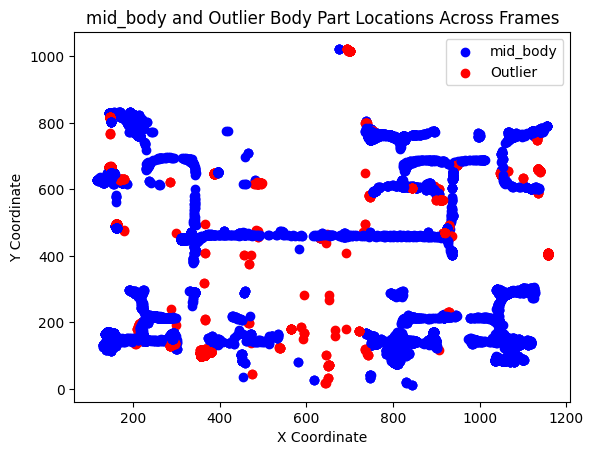

In [14]:
import matplotlib.pyplot as plt

# Iterate through each row in the outliers_df
for index, row in outliers_df.iterrows():
    # Extract the nose and outlier body part coordinates
    nose_x, nose_y = row['mid_body']['x'], row['mid_body']['y']
    outlier_body = row['outlier_body'].to_string().replace(' ', '')
    outlier_x, outlier_y = row[outlier_body]['x'], row[outlier_body]['y']
    
    # Plot the nose and outlier body part
    plt.scatter(nose_x, nose_y, color='blue', label='mid_body' if index == 0 else "")
    plt.scatter(outlier_x, outlier_y, color='red', label='Outlier' if index == 0 else "")

# Add labels and legend
plt.xlabel('X Coordinate')
plt.ylabel('Y Coordinate')
plt.title('mid_body and Outlier Body Part Locations Across Frames')
plt.legend()
plt.show()